# SafeFlow — Congestion onset across prediction horizons

Retest the findings from `03_congestion_onset_analysis.ipynb` at **10, 15, 20, and 30 minutes**, with 30 minutes as the reference. Use the saved D12 northbound mainline table, the same first temporal fold, speed thresholds, feature bundles, and model settings. No shared notebook kernel is required.

Questions:

1. Does persistence remain substantially worse during transitions than stable traffic?
2. Do recent history, flow/occupancy, and upstream observations improve ranking at shorter horizons?
3. Does Random Forest still improve on logistic regression?
4. How do precision, recall, false warnings, and average precision change with warning horizon?

The label means **congested exactly at t + horizon**, rather than any congestion within that interval. All horizons keep the same 30-minute input history. Observations are weekday daytime station-time rows, not independent congestion episodes. The final July–December 2025 holdout is not loaded or scored.

## Results from the completed default run

These are measured results for **all 46 stations**, training January–June 2023 and validating July–December 2023, with **300-tree Random Forests** and the upstream-augmented feature set. The table reports each horizon's native validation cohort. Cutoffs were selected separately to achieve at least 80% recall.

| Horizon | Eligible rows | Onset prevalence | Average precision | Precision at ≥80% recall | Achieved recall |
|---|---:|---:|---:|---:|---:|
| 10 min | 324,294 | 0.23% | 0.151 | 2.54% | 80.05% |
| 15 min | 319,958 | 0.49% | 0.211 | 4.21% | 80.05% |
| 20 min | 316,229 | 0.79% | 0.255 | 6.00% | 80.00% |
| 30 min | 309,745 | 1.35% | 0.322 | 8.94% | 80.01% |

**Interpretation.** Shorter windows do not automatically improve these rare-transition warning metrics: requiring a ≥50 mph origin and a ≤40 mph endpoint gives substantially fewer positives as the horizon shrinks. Both the label's event frequency and the available intervention time change. Use the common-origin tables and cohort-specific prevalence below to distinguish changes in evaluation population from changes in ranking. Common-origin evaluation still uses a different label at each horizon and native training populations.

**Common-origin check:** Random Forest average precision / precision at the recall target are **10 min: 0.247 / 3.22%**; **15 min: 0.262 / 3.12%**; **20 min: 0.245 / 2.72%**; **30 min: 0.196 / 2.36%**.

These comparisons are from one development fold, not the final holdout. Average precision is prevalence-sensitive; the per-horizon tables also report lift relative to prevalence, false-warning counts, feature increments, and persistence errors by regime. This static summary describes the saved default run; update it after changing configuration and rerunning.

Saved result folder: `results/congestion_horizon_comparison/2026-10-28_134810_584716`.


**The cohort changes the conclusion.** On common origins, 10-minute precision at the recall target is 3.22%, versus 2.36% at 30 minutes, reversing the native-sample ordering. Requiring clear labels at every horizon can exclude gradual or borderline transitions. Common-origin membership uses future outcomes and is a retrospective sensitivity analysis, not a real-time deployment eligibility rule. No horizon is established as universally best by these single-fold comparisons.


In [1]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, precision_recall_curve, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Start this notebook in the SafeFlow project or a subdirectory")
PROCESSED_DIR = ROOT / "data" / "processed"
FEATURE_FILE = PROCESSED_DIR / "main.parquet"
FOLDS_FILE = PROCESSED_DIR / "temporal_folds.json"
STATION_ORDER_FILE = PROCESSED_DIR / "i5_nb_station_order.csv"
RESULTS_DIR = ROOT / "results" / "congestion_horizon_comparison"

HORIZONS = [10, 15, 20, 30]
FOLD_INDEX = 0  # same development fold as the original notebook; try 1, 2, 3 later
FREE_FLOW_THRESHOLD, CONGESTED_THRESHOLD = 50.0, 40.0
REGIME_THRESHOLD, TARGET_MIN_OBSERVED = 45.0, 80
TARGET_RECALL = 0.80
RF_TREES, RF_DEPTH, RF_MIN_LEAF = 300, 12, 10
RANDOM_STATE = 42
RF_N_JOBS = -1  # reduce if memory is limited
STATION_IDS = None  # None = all 46 northbound stations; subset only for a smoke run

# Preserve the original analysis's names so the feature definitions are identical.
TIMESTAMP_COL, STATION_COL = "Timestamp", "Station"
SPEED_COL, FLOW_COL, OCC_COL, OBS_COL = "Avg Speed", "Total Flow", "Avg Occupancy", "% Observed"
assert HORIZONS and len(set(HORIZONS)) == len(HORIZONS)
assert all(h > 0 and h % 5 == 0 for h in HORIZONS)
assert 0 < TARGET_RECALL <= 1
for file in [FEATURE_FILE, FOLDS_FILE]:
    if not file.exists():
        raise FileNotFoundError(f"Missing {file}. Run the export cell in data_and_features.ipynb first")
fold_config = json.loads(FOLDS_FILE.read_text(encoding="utf-8"))
selected_fold = fold_config["folds"][FOLD_INDEX]
train_start = pd.Timestamp(fold_config["train_start"])
val_start, val_end = pd.Timestamp(selected_fold["val_start"]), pd.Timestamp(selected_fold["val_end"])
test_start = pd.Timestamp(fold_config["test_start"])
assert train_start < val_start < val_end <= test_start
print("Project:", ROOT, flush=True)
print("Horizons:", HORIZONS, "minutes", flush=True)
print("Training labels before:", val_start, "Validation labels before:", val_end, flush=True)
print("Final holdout starts:", test_start, "— excluded from this experiment", flush=True)

Project: C:\Erdos\Project\safeflow
Horizons: [10, 15, 20, 30] minutes
Training labels before: 2023-07-01 00:00:00 Validation labels before: 2024-01-01 00:00:00
Final holdout starts: 2025-07-01 00:00:00 — excluded from this experiment


## 1. Load only the selected development period

Read the saved feature table once, filter to northbound observations, and exclude dates at or after the selected validation endpoint. The original preparation already restricts the source to D12 I-5 mainline stations and weekdays 06:00–19:55. Changing the horizon does not change the calendar split. The `forecast_minutes` field in the saved fold file describes the old experiment; this notebook reuses its **dates**, rebuilding labels and boundary purges separately for each horizon.

In [2]:
print("Loading saved mainline observations…", flush=True)
raw_columns = ["timestamp", "station", "speed", "flow", "occupancy", "pct_observed", "direction"]
raw = pd.read_parquet(FEATURE_FILE, columns=raw_columns, engine="pyarrow",
                      filters=[("timestamp", ">=", train_start), ("timestamp", "<", val_end)])
raw["timestamp"] = pd.to_datetime(raw["timestamp"], errors="raise")
raw = raw.loc[raw["direction"].astype(str).str.upper().str.strip().eq("N")].copy()
if STATION_IDS is not None:
    raw = raw.loc[raw["station"].isin(STATION_IDS)].copy()
corridor = raw.rename(columns={"timestamp": TIMESTAMP_COL, "station": STATION_COL,
    "speed": SPEED_COL, "flow": FLOW_COL, "occupancy": OCC_COL, "pct_observed": OBS_COL})
base_cols = [STATION_COL, TIMESTAMP_COL, SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]
base = corridor[base_cols].copy()
for column in [SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]:
    base[column] = pd.to_numeric(base[column], errors="coerce")
duplicate_rows = int(base.duplicated([STATION_COL, TIMESTAMP_COL]).sum())
if duplicate_rows:
    base = base.groupby([STATION_COL, TIMESTAMP_COL], as_index=False)[
        [SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]].mean()
base = base.sort_values([TIMESTAMP_COL, STATION_COL]).reset_index(drop=True)
if base.empty:
    raise ValueError("No northbound observations in the selected development period")
assert base[TIMESTAMP_COL].max() < val_end <= test_start
del raw, corridor
print(f"Loaded {len(base):,} rows, {base[STATION_COL].nunique()} stations; duplicates averaged: {duplicate_rows}", flush=True)
display(base.head())

Loading saved mainline observations…
Loaded 2,006,336 rows, 46 stations; duplicates averaged: 0


,Station,Timestamp,Avg Speed,Total Flow,Avg Occupancy,% Observed
0,1205045,2023-01-02 06:00:00,71.7,168.0,0.0298,80.0
1,1205071,2023-01-02 06:00:00,59.9,188.0,0.0359,0.0
2,1205088,2023-01-02 06:00:00,69.6,193.0,0.0293,80.0
3,1205135,2023-01-02 06:00:00,71.5,191.0,0.0285,100.0
4,1205152,2023-01-02 06:00:00,60.2,212.0,0.0394,100.0


## 2. Build the same historical predictors once

Features are independent of prediction horizon, so compute them once and reuse them. Exact-time joins preserve elapsed lag durations across gaps. Missing history at the start of the retained daily window is expected. Median imputation and scaling are fitted separately on each horizon's training set. The weekend indicator is constant in this weekday-only data.

In [3]:
features = base.copy().rename(columns={
    SPEED_COL: "speed_now",
    FLOW_COL: "flow_now",
    OCC_COL: "occupancy_now",
    OBS_COL: "observed_now",
})

lag_source = base.copy()

def add_exact_lag(frame, source, columns, lag_min, suffix):
    lag = source[[STATION_COL, TIMESTAMP_COL] + columns].copy()
    lag[TIMESTAMP_COL] = lag[TIMESTAMP_COL] + pd.Timedelta(minutes=lag_min)
    lag = lag.rename(columns={c: f"{c}_{suffix}" for c in columns})
    return frame.merge(lag, on=[STATION_COL, TIMESTAMP_COL], how="left", validate="one_to_one")

for lag_min in [5, 10, 15, 30]:
    features = add_exact_lag(features, lag_source, [SPEED_COL], lag_min, f"lag_{lag_min}min")
for lag_min in [5, 15, 30]:
    features = add_exact_lag(features, lag_source, [FLOW_COL, OCC_COL], lag_min, f"lag_{lag_min}min")

features = features.rename(columns={
    f"{SPEED_COL}_lag_5min": "speed_lag_5",
    f"{SPEED_COL}_lag_10min": "speed_lag_10",
    f"{SPEED_COL}_lag_15min": "speed_lag_15",
    f"{SPEED_COL}_lag_30min": "speed_lag_30",
    f"{FLOW_COL}_lag_5min": "flow_lag_5",
    f"{FLOW_COL}_lag_15min": "flow_lag_15",
    f"{FLOW_COL}_lag_30min": "flow_lag_30",
    f"{OCC_COL}_lag_5min": "occ_lag_5",
    f"{OCC_COL}_lag_15min": "occ_lag_15",
    f"{OCC_COL}_lag_30min": "occ_lag_30",
})

speed_recent = ["speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30"]
features["speed_trend_15"] = features["speed_now"] - features["speed_lag_15"]
features["speed_recent_mean"] = features[speed_recent].mean(axis=1)
features["speed_recent_std"] = features[speed_recent].std(axis=1)
features["flow_trend_15"] = features["flow_now"] - features["flow_lag_15"]
features["occupancy_trend_15"] = features["occupancy_now"] - features["occ_lag_15"]

hour_fraction = features[TIMESTAMP_COL].dt.hour + features[TIMESTAMP_COL].dt.minute / 60
features["hour_sin"] = np.sin(2 * np.pi * hour_fraction / 24)
features["hour_cos"] = np.cos(2 * np.pi * hour_fraction / 24)
features["is_weekend"] = (features[TIMESTAMP_COL].dt.dayofweek >= 5).astype(int)

print("Feature table shape:", features.shape)
display(features.head())

Feature table shape: (2006336, 24)


,Station,Timestamp,speed_now,flow_now,occupancy_now,observed_now,speed_lag_5,speed_lag_10,speed_lag_15,speed_lag_30,flow_lag_5,occ_lag_5,flow_lag_15,occ_lag_15,flow_lag_30,occ_lag_30,speed_trend_15,speed_recent_mean,speed_recent_std,flow_trend_15,occupancy_trend_15,hour_sin,hour_cos,is_weekend
0,1205045,2023-01-02 06:00:00,71.7,168.0,0.0298,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.7,NaN,NaN,NaN,1.0,6.123234e-17,0
1,1205071,2023-01-02 06:00:00,59.9,188.0,0.0359,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.9,NaN,NaN,NaN,1.0,6.123234e-17,0
2,1205088,2023-01-02 06:00:00,69.6,193.0,0.0293,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69.6,NaN,NaN,NaN,1.0,6.123234e-17,0
3,1205135,2023-01-02 06:00:00,71.5,191.0,0.0285,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.5,NaN,NaN,NaN,1.0,6.123234e-17,0
4,1205152,2023-01-02 06:00:00,60.2,212.0,0.0394,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.2,NaN,NaN,NaN,1.0,6.123234e-17,0


In [4]:
SPATIAL_FEATURES_AVAILABLE = False

if STATION_ORDER_FILE.exists():
    station_order = pd.read_csv(STATION_ORDER_FILE)
    required = {STATION_COL, "corridor_order"}
    missing = required - set(station_order.columns)
    if missing:
        raise ValueError(f"Station-order file missing columns: {missing}")

    station_order = (
        station_order[[STATION_COL, "corridor_order"]]
        .drop_duplicates()
        .sort_values("corridor_order")
    )
    station_order["upstream_station"] = station_order[STATION_COL].shift(1)
    station_map = station_order[[STATION_COL, "upstream_station"]].dropna()

    features = features.merge(station_map, on=STATION_COL, how="left", validate="many_to_one")

    upstream_now = features[[
        STATION_COL, TIMESTAMP_COL, "speed_now", "flow_now", "occupancy_now", "speed_lag_15"
    ]].copy()
    upstream_now = upstream_now.rename(columns={
        STATION_COL: "upstream_station",
        "speed_now": "upstream_speed_now",
        "flow_now": "upstream_flow_now",
        "occupancy_now": "upstream_occupancy_now",
        "speed_lag_15": "upstream_speed_lag_15",
    })

    features = features.merge(
        upstream_now,
        on=["upstream_station", TIMESTAMP_COL],
        how="left",
        validate="many_to_one",
    )
    features["upstream_speed_trend_15"] = features["upstream_speed_now"] - features["upstream_speed_lag_15"]
    SPATIAL_FEATURES_AVAILABLE = True
    print("Verified upstream spatial features created.")
else:
    print("No verified station-order file found; spatial feature set will be skipped.")

Verified upstream spatial features created.


In [5]:
FEATURE_SETS = {
    "A_current_speed": ["speed_now"],
    "B_local_history": [
        "speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30",
        "speed_trend_15", "speed_recent_mean", "speed_recent_std",
        "hour_sin", "hour_cos", "is_weekend",
    ],
    "C_plus_flow_occupancy": [
        "speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30",
        "speed_trend_15", "speed_recent_mean", "speed_recent_std",
        "flow_now", "flow_lag_5", "flow_lag_15", "flow_lag_30", "flow_trend_15",
        "occupancy_now", "occ_lag_5", "occ_lag_15", "occ_lag_30", "occupancy_trend_15",
        "observed_now", "hour_sin", "hour_cos", "is_weekend",
    ],
}

if SPATIAL_FEATURES_AVAILABLE:
    FEATURE_SETS["D_plus_upstream"] = FEATURE_SETS["C_plus_flow_occupancy"] + [
        "upstream_speed_now", "upstream_speed_lag_15", "upstream_speed_trend_15",
        "upstream_flow_now", "upstream_occupancy_now",
    ]

for name, cols in FEATURE_SETS.items():
    print(name, ":", len(cols), "features")

A_current_speed : 1 features
B_local_history : 11 features
C_plus_flow_occupancy : 22 features
D_plus_upstream : 27 features


## 3. Exact future labels, eligibility, and comparable origins

For each horizon, positive = current speed ≥50 mph and future speed ≤40 mph; negative = current speed ≥50 mph and future speed ≥50 mph. Intermediate future speeds are excluded, and future observation coverage must be ≥80%.

**Native cohort:** all eligible origins for that horizon. This reproduces the original 30-minute classifier population and supports a comparison with its saved results.

**Common-origin cohort:** the intersection of eligible origins across every configured horizon, purged using the longest horizon. All models at a given horizon are scored on identical rows, and all horizons use the same common validation origins. Labels can still differ with horizon. Each model is trained on its native training population; the common-origin analysis controls evaluation origins, not training eligibility. This restricted intersection can exclude interesting borderline transitions, so inspect both cohorts and their prevalence.

Common-origin membership depends on future endpoint labels. Use it for retrospective sensitivity analysis; it cannot be applied as an availability filter when issuing real-time warnings.


In [6]:
lookup = base.set_index([STATION_COL, TIMESTAMP_COL])[[SPEED_COL, OBS_COL]]
origin_time = features[TIMESTAMP_COL]
labels, native_train, native_val = {}, {}, {}
population_rows = []

def exact_future(horizon):
    keys = pd.MultiIndex.from_arrays(
        [features[STATION_COL].to_numpy(), (origin_time + pd.Timedelta(minutes=horizon)).to_numpy()],
        names=[STATION_COL, TIMESTAMP_COL])
    future = lookup.reindex(keys)
    return pd.DataFrame({"future_speed": future[SPEED_COL].to_numpy(),
                         "future_observed": future[OBS_COL].to_numpy()}, index=features.index)

for horizon in HORIZONS:
    frame = exact_future(horizon)
    frame["label"] = np.where(frame["future_speed"] <= CONGESTED_THRESHOLD, 1.0,
                               np.where(frame["future_speed"] >= FREE_FLOW_THRESHOLD, 0.0, np.nan))
    eligible = ((features["speed_now"] >= FREE_FLOW_THRESHOLD)
                & (frame["future_observed"] >= TARGET_MIN_OBSERVED) & frame["label"].notna())
    target_time = origin_time + pd.Timedelta(minutes=horizon)
    frame["eligible"] = eligible
    labels[horizon] = frame
    native_train[horizon] = eligible & (origin_time >= train_start) & (target_time < val_start)
    native_val[horizon] = eligible & (origin_time >= val_start) & (target_time < val_end)

common_eligible = np.logical_and.reduce([labels[h]["eligible"].to_numpy() for h in HORIZONS])
common_train = common_eligible & (origin_time >= train_start) & (origin_time + pd.Timedelta(minutes=max(HORIZONS)) < val_start)
common_val = common_eligible & (origin_time >= val_start) & (origin_time + pd.Timedelta(minutes=max(HORIZONS)) < val_end)
if not common_val.any():
    raise ValueError("No common-origin validation observations remain")

for horizon in HORIZONS:
    for cohort, train_mask, val_mask in [("native", native_train[horizon], native_val[horizon]),
                                         ("common_origins", common_train, common_val)]:
        y = labels[horizon]["label"]
        population_rows.append(dict(horizon_min=horizon, cohort=cohort,
            train_eligible_rows=int(train_mask.sum()), validation_rows=int(val_mask.sum()),
            validation_positives=int(y.loc[val_mask].sum()), validation_prevalence=y.loc[val_mask].mean()))
populations = pd.DataFrame(population_rows)
display(populations.round(5))
print("Common-origin training counts above describe intersection eligibility; models train on native rows.", flush=True)

,horizon_min,cohort,train_eligible_rows,validation_rows,validation_positives,validation_prevalence
0,10,native,451089,324294,737,0.00227
1,10,common_origins,419693,299852,441,0.00147
2,15,native,445335,319958,1574,0.00492
3,15,common_origins,419693,299852,505,0.00168
4,20,native,440409,316229,2500,0.00791
5,20,common_origins,419693,299852,578,0.00193
6,30,native,431692,309745,4183,0.01350
7,30,common_origins,419693,299852,1092,0.00364


Common-origin training counts above describe intersection eligibility; models train on native rows.


**How to read the population table.** A shorter horizon can have fewer large speed drops, even on identical origins. Average precision depends on positive prevalence, so an increase or decrease in the raw score alone does not establish that a horizon is operationally easier. `AP_lift` below divides average precision by the cohort's own positive fraction; it provides context rather than a prevalence-independent quality measure.

## 4. Retest persistence by traffic regime

Use the same 45 mph regime boundary as the original diagnostic. To avoid mixing development and holdout dates, these descriptive errors use **validation only**, before the stricter classifier target-quality and label-gap filters. Native regression cohorts require current and future speeds; a second common regression cohort requires endpoints at every horizon. That cohort differs from the stricter classification intersection. The original notebook's all-period 30-minute regression metrics are therefore not expected to match these validation-only numbers.

,horizon_min,cohort,regime,n,MAE_mph,RMSE_mph
0,10,native,Congested → Congested,87892,2.689,3.857
1,10,native,Congested → Free,13541,7.975,9.754
2,10,native,Free → Congested,13890,7.307,9.134
3,10,native,Free → Free,874413,1.168,1.998
4,10,common_origins,Congested → Congested,87082,2.680,3.841
5,10,common_origins,Congested → Free,12938,7.801,9.570
6,10,common_origins,Free → Congested,13745,7.290,9.104
7,10,common_origins,Free → Free,852051,1.163,1.985
8,15,native,Congested → Congested,84554,3.050,4.375
9,15,native,Congested → Free,16611,10.018,12.242


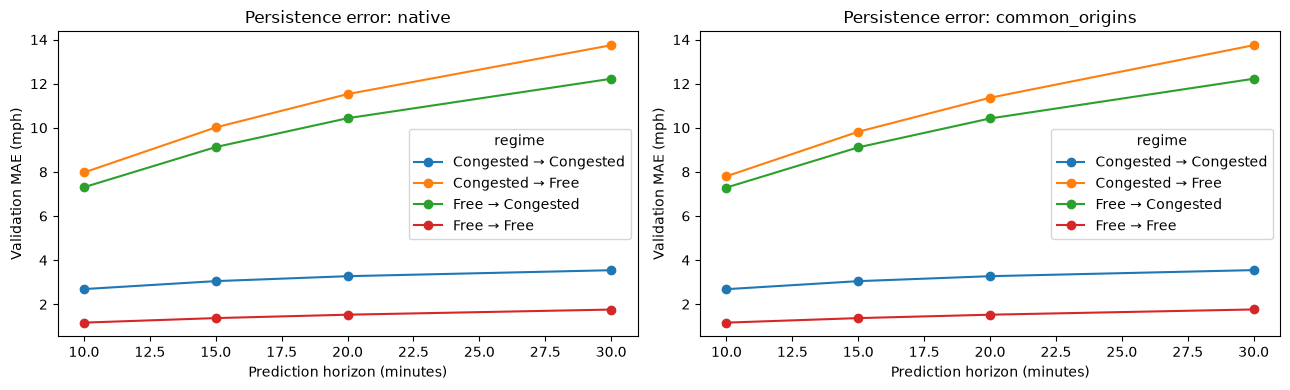

In [7]:
regression_eligible = {h: features["speed_now"].notna() & labels[h]["future_speed"].notna() for h in HORIZONS}
common_regression = np.logical_and.reduce([mask.to_numpy() for mask in regression_eligible.values()])
common_regression &= ((origin_time >= val_start) & (origin_time + pd.Timedelta(minutes=max(HORIZONS)) < val_end)).to_numpy()
regime_rows = []
for horizon in HORIZONS:
    native_mask = regression_eligible[horizon] & (origin_time >= val_start) & (origin_time + pd.Timedelta(minutes=horizon) < val_end)
    for cohort, mask in [("native", native_mask), ("common_origins", common_regression)]:
        current = features.loc[mask, "speed_now"]
        future = labels[horizon].loc[mask, "future_speed"]
        regimes = np.select([(current >= REGIME_THRESHOLD) & (future >= REGIME_THRESHOLD),
                             (current >= REGIME_THRESHOLD) & (future < REGIME_THRESHOLD),
                             (current < REGIME_THRESHOLD) & (future < REGIME_THRESHOLD)],
                            ["Free → Free", "Free → Congested", "Congested → Congested"], default="Congested → Free")
        errors = pd.DataFrame({"regime": regimes, "error": (future - current).to_numpy()})
        for regime, group in errors.groupby("regime"):
            regime_rows.append(dict(horizon_min=horizon, cohort=cohort, regime=regime, n=len(group),
                                    MAE_mph=group.error.abs().mean(), RMSE_mph=np.sqrt((group.error ** 2).mean())))
regime_metrics = pd.DataFrame(regime_rows)
display(regime_metrics.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cohort in zip(axes, ["native", "common_origins"]):
    regime_metrics.loc[regime_metrics.cohort.eq(cohort)].pivot(index="horizon_min", columns="regime", values="MAE_mph").plot(marker="o", ax=ax)
    ax.set(title=f"Persistence error: {cohort}", xlabel="Prediction horizon (minutes)", ylabel="Validation MAE (mph)")
plt.tight_layout()
plt.show()

**Interpretation.** Check whether onset/recovery errors remain larger than stable-state errors and whether the gap narrows at shorter horizons. The regime rules select endpoint changes, so larger transition error is partly built into the definition; it does not by itself show that those transitions can be predicted. Use the counts to identify sparse regimes and do not treat adjacent five-minute rows as independent events.

## 5. Train comparable classifiers and score both cohorts

At every horizon, train logistic regression on A/B/C/D as available and train Random Forest on the **same richest available feature bundle** across all horizons. This avoids changing Random Forest inputs in response to horizon-specific validation rankings. In the original saved run, D was the best logistic bundle and was also used by Random Forest. The tree count/depth/leaf size and class weights match that experiment.

Fit on native training rows; evaluate every model on both validation cohorts. Report the default 0.5 cutoff and a separately chosen cutoff maximizing precision subject to recall ≥80%. All feature selection, model comparisons, and cutoff choices remain development results from this validation fold; their scores are not unbiased final-test estimates. Scores from class-weighted models are not established to be calibrated probabilities.

This is the expensive cell: four horizons require up to **16 logistic fits and four 300-tree forests**. Progress prints before every fit and checkpoints are saved after each horizon. Reduce `RF_N_JOBS` if memory is constrained. A smoke test with fewer trees/stations is not a replacement for the full comparison.

In [8]:
def score_metrics(y, prob, threshold):
    predicted = prob >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    prevalence = float(np.mean(y))
    ap = average_precision_score(y, prob) if np.sum(y) else np.nan
    return dict(n=len(y), positives=int(np.sum(y)), prevalence=prevalence,
                PR_AUC=ap, AP_lift=ap / prevalence if prevalence else np.nan,
                ROC_AUC=roc_auc_score(y, prob) if np.unique(y).size == 2 else np.nan,
                Precision=precision_score(y, predicted, zero_division=0),
                Recall=recall_score(y, predicted, zero_division=0),
                F1=f1_score(y, predicted, zero_division=0),
                true_positives=int(tp), false_positives=int(fp), false_negatives=int(fn), true_negatives=int(tn),
                warnings_per_1000=1000 * float(np.mean(predicted)),
                false_warnings_per_true_onset=fp / tp if tp else np.nan)

def choose_threshold(y, prob):
    if np.unique(y).size < 2:
        return np.nan
    precision, recall, thresholds = precision_recall_curve(y, prob)
    table = pd.DataFrame(dict(threshold=thresholds, precision=precision[:-1], recall=recall[:-1]))
    eligible = table.loc[table.recall >= TARGET_RECALL]
    return float(eligible.sort_values(["precision", "threshold"], ascending=False).iloc[0].threshold) if len(eligible) else np.nan

run_dir = RESULTS_DIR / datetime.now().strftime("%Y-%m-%d_%H%M%S_%f")
run_dir.mkdir(parents=True, exist_ok=False)
print("Run checkpoints:", run_dir, flush=True)
result_rows, curve_rows = [], []
rf_feature_set = list(FEATURE_SETS)[-1]
for horizon in HORIZONS:
    started = perf_counter()
    train_mask = native_train[horizon]
    train_y = labels[horizon].loc[train_mask, "label"].astype(int)
    if train_y.nunique() != 2:
        raise ValueError(f"{horizon} min training needs both classes; inspect populations")
    specs = [("Logistic regression", name, cols) for name, cols in FEATURE_SETS.items()]
    specs.append(("Random Forest", rf_feature_set, FEATURE_SETS[rf_feature_set]))
    for model_name, feature_set, cols in specs:
        print(f"[{horizon} min] fitting {model_name} / {feature_set} on {len(train_y):,} rows…", flush=True)
        if model_name == "Logistic regression":
            pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                             ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
        else:
            pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("model", RandomForestClassifier(n_estimators=RF_TREES, max_depth=RF_DEPTH,
                               min_samples_leaf=RF_MIN_LEAF, class_weight="balanced_subsample",
                               random_state=RANDOM_STATE, n_jobs=RF_N_JOBS))])
        pipe.fit(features.loc[train_mask, cols], train_y)
        val_index = features.index[native_val[horizon]]
        if len(val_index) == 0:
            raise ValueError(f"{horizon} min has no native validation rows")
        probabilities = pd.Series(pipe.predict_proba(features.loc[val_index, cols])[:, 1], index=val_index)
        for cohort, mask in [("native", native_val[horizon]), ("common_origins", common_val)]:
            y = labels[horizon].loc[mask, "label"].astype(int).to_numpy()
            prob = probabilities.loc[features.index[mask]].to_numpy()
            if len(y) == 0 or np.unique(y).size != 2:
                raise ValueError(f"{horizon} min / {cohort} validation needs both classes")
            chosen_threshold = choose_threshold(y, prob)
            for operating_point, threshold in [("default_0.5", 0.5), ("target_recall", chosen_threshold)]:
                if not np.isfinite(threshold):
                    continue
                result_rows.append(dict(horizon_min=horizon, cohort=cohort, model=model_name,
                    feature_set=feature_set, operating_point=operating_point, threshold=threshold,
                    **score_metrics(y, prob, threshold)))
            p, r, _ = precision_recall_curve(y, prob)
            # Compact representation for plots, keeping full-precision metrics above.
            positions = np.unique(np.linspace(0, len(p) - 1, min(1000, len(p))).astype(int))
            curve_rows.extend(dict(horizon_min=horizon, cohort=cohort, model=model_name, feature_set=feature_set,
                                   precision=float(p[j]), recall=float(r[j])) for j in positions)
        del pipe
    results = pd.DataFrame(result_rows)
    results.to_csv(run_dir / "classifier_metrics.csv", index=False)
    print(f"[{horizon} min] complete in {perf_counter() - started:.1f}s; checkpoint saved", flush=True)
curves = pd.DataFrame(curve_rows)
display(results.loc[results.operating_point.eq("default_0.5"),
    ["horizon_min", "cohort", "model", "feature_set", "n", "prevalence", "PR_AUC", "AP_lift", "Precision", "Recall", "F1"]].round(4))

Run checkpoints: C:\Erdos\Project\safeflow\results\congestion_horizon_comparison\2026-10-28_134810_584716
[10 min] fitting Logistic regression / A_current_speed on 451,089 rows…
[10 min] fitting Logistic regression / B_local_history on 451,089 rows…
[10 min] fitting Logistic regression / C_plus_flow_occupancy on 451,089 rows…
[10 min] fitting Logistic regression / D_plus_upstream on 451,089 rows…
[10 min] fitting Random Forest / D_plus_upstream on 451,089 rows…
[10 min] complete in 135.4s; checkpoint saved
[15 min] fitting Logistic regression / A_current_speed on 445,335 rows…
[15 min] fitting Logistic regression / B_local_history on 445,335 rows…
[15 min] fitting Logistic regression / C_plus_flow_occupancy on 445,335 rows…
[15 min] fitting Logistic regression / D_plus_upstream on 445,335 rows…
[15 min] fitting Random Forest / D_plus_upstream on 445,335 rows…
[15 min] complete in 118.7s; checkpoint saved
[20 min] fitting Logistic regression / A_current_speed on 440,409 rows…
[20 min] f

,horizon_min,cohort,model,feature_set,n,prevalence,PR_AUC,AP_lift,Precision,Recall,F1
0,10,native,Logistic regression,A_current_speed,324294,0.0023,0.0218,9.5808,0.0112,0.7965,0.0221
2,10,common_origins,Logistic regression,A_current_speed,299852,0.0015,0.0219,14.9081,0.0085,0.8186,0.0169
4,10,native,Logistic regression,B_local_history,324294,0.0023,0.0664,29.1965,0.0127,0.8128,0.0250
6,10,common_origins,Logistic regression,B_local_history,299852,0.0015,0.0780,53.0368,0.0100,0.8481,0.0197
8,10,native,Logistic regression,C_plus_flow_occupancy,324294,0.0023,0.0553,24.3447,0.0141,0.8358,0.0277
10,10,common_origins,Logistic regression,C_plus_flow_occupancy,299852,0.0015,0.0563,38.3086,0.0112,0.8662,0.0221
12,10,native,Logistic regression,D_plus_upstream,324294,0.0023,0.0593,26.1010,0.0145,0.8399,0.0285
14,10,common_origins,Logistic regression,D_plus_upstream,299852,0.0015,0.0662,44.9942,0.0115,0.8685,0.0226
16,10,native,Random Forest,D_plus_upstream,324294,0.0023,0.1510,66.4384,0.0796,0.5373,0.1386
18,10,common_origins,Random Forest,D_plus_upstream,299852,0.0015,0.2471,168.0146,0.0922,0.6599,0.1618


## 6. Compare feature gains, model ranking, and warning burden

Use the same cohort in each panel. Average precision summarizes ranking, whereas precision/recall/F1 refer to one cutoff. The recall-target cutoff may improve detection while reducing precision and F1. Comparing precision at the same recall is more relevant to a warning policy than comparing every model at the arbitrary 0.5 cutoff. Each horizon/cohort gets its own tuned cutoff; there is no single shared operational threshold.

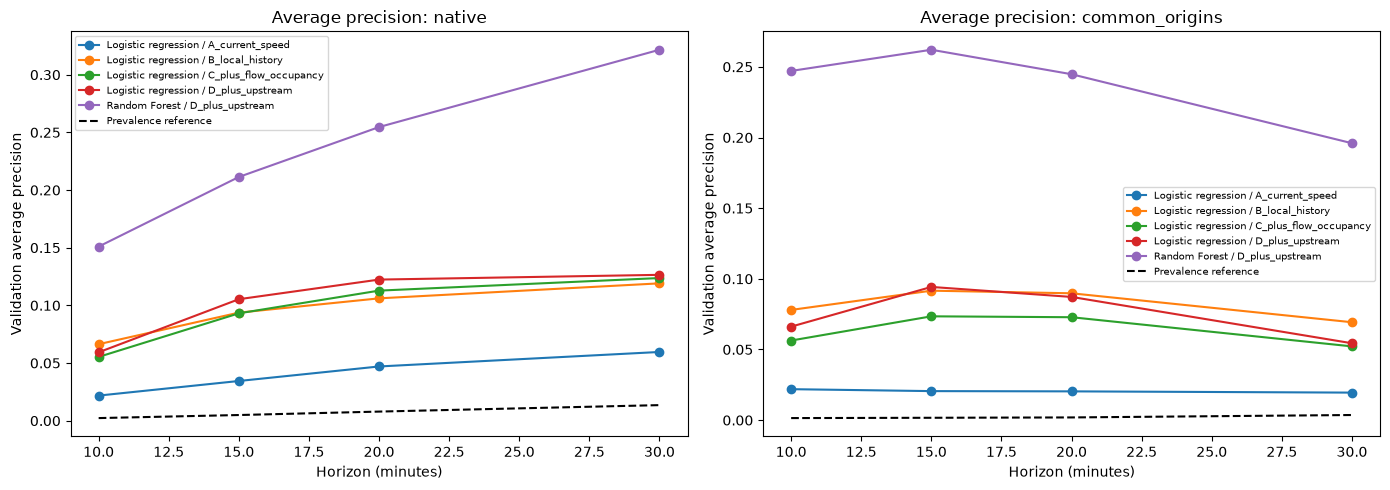

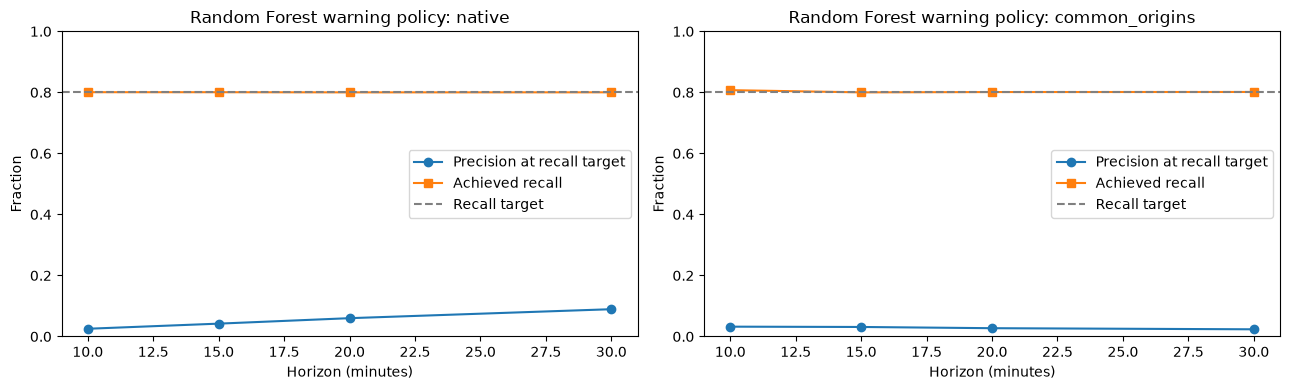

,horizon_min,cohort,threshold,PR_AUC,Precision,Recall,F1,false_positives,false_negatives,warnings_per_1000,false_warnings_per_true_onset
17,10,native,0.1916,0.1510,0.0254,0.8005,0.0491,22682,147,71.7620,38.4441
19,10,common_origins,0.2688,0.2471,0.0322,0.8073,0.0620,10688,85,36.8315,30.0225
37,15,native,0.2264,0.2114,0.0421,0.8005,0.0801,28643,314,93.4591,22.7325
39,15,common_origins,0.3373,0.2621,0.0312,0.8000,0.0601,12538,101,43.1613,31.0347
57,20,native,0.2479,0.2546,0.0600,0.8000,0.1117,31313,500,105.3445,15.6565
59,20,common_origins,0.3460,0.2448,0.0272,0.8010,0.0526,16563,115,56.7813,35.7732
77,30,native,0.2913,0.3217,0.0894,0.8001,0.1609,34076,836,120.8187,10.1811
79,30,common_origins,0.2594,0.1960,0.0236,0.8013,0.0458,36249,217,123.8077,41.4274


In [9]:
ranking = results.loc[results.operating_point.eq("default_0.5")].copy()
operating = results.loc[results.operating_point.eq("target_recall")].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cohort in zip(axes, ["native", "common_origins"]):
    table = ranking.loc[ranking.cohort.eq(cohort)].copy()
    table["series"] = table["model"] + " / " + table["feature_set"]
    table.pivot(index="horizon_min", columns="series", values="PR_AUC").plot(marker="o", ax=ax)
    reference = table.groupby("horizon_min").prevalence.first()
    ax.plot(reference.index, reference, "k--", label="Prevalence reference")
    ax.set(title=f"Average precision: {cohort}", xlabel="Horizon (minutes)", ylabel="Validation average precision")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cohort in zip(axes, ["native", "common_origins"]):
    rf_operating = operating.loc[operating.cohort.eq(cohort) & operating.model.eq("Random Forest")].sort_values("horizon_min")
    ax.plot(rf_operating.horizon_min, rf_operating.Precision, marker="o", label="Precision at recall target")
    ax.plot(rf_operating.horizon_min, rf_operating.Recall, marker="s", label="Achieved recall")
    ax.axhline(TARGET_RECALL, linestyle="--", color="gray", label="Recall target")
    ax.set(title=f"Random Forest warning policy: {cohort}", xlabel="Horizon (minutes)", ylabel="Fraction", ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()
display(operating.loc[operating.model.eq("Random Forest"), ["horizon_min", "cohort", "threshold", "PR_AUC",
    "Precision", "Recall", "F1", "false_positives", "false_negatives", "warnings_per_1000", "false_warnings_per_true_onset"]].round(4))

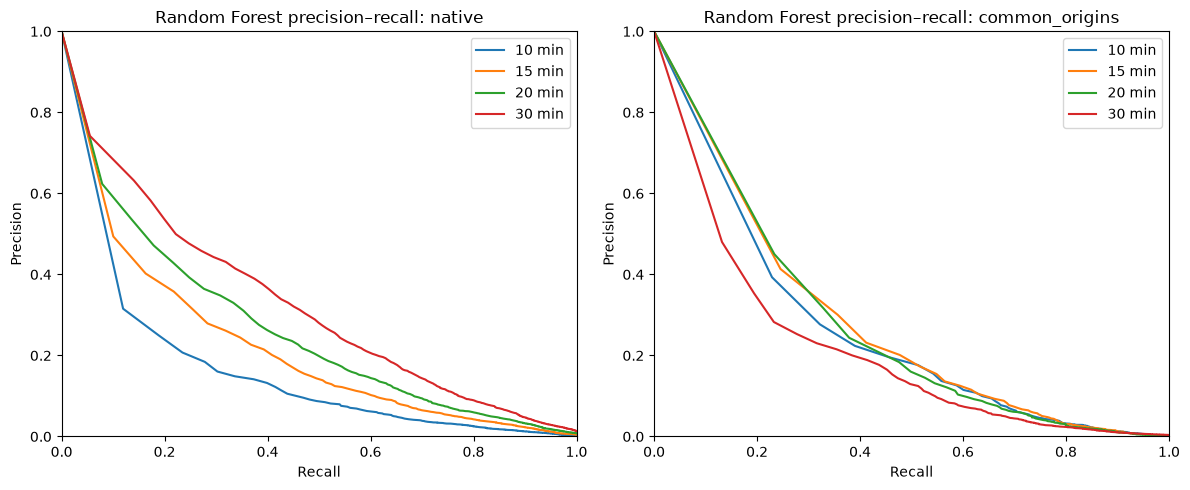

feature_set                 A_current_speed  ...  upstream_gain
cohort         horizon_min                   ...               
common_origins 10                    0.0219  ...         0.0098
               15                    0.0206  ...         0.0208
               20                    0.0204  ...         0.0144
               30                    0.0195  ...         0.0022
native         10                    0.0218  ...         0.0040
               15                    0.0344  ...         0.0123
               20                    0.0470  ...         0.0096
               30                    0.0596  ...         0.0028

[8 rows x 7 columns]

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cohort in zip(axes, ["native", "common_origins"]):
    subset = curves.loc[curves.cohort.eq(cohort) & curves.model.eq("Random Forest")]
    for horizon, group in subset.groupby("horizon_min"):
        ax.plot(group.recall, group.precision, label=f"{horizon} min")
    ax.set(title=f"Random Forest precision–recall: {cohort}", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()

feature_gains = ranking.loc[ranking.model.eq("Logistic regression")].pivot(
    index=["cohort", "horizon_min"], columns="feature_set", values="PR_AUC")
for old, new, name in [("A_current_speed", "B_local_history", "history_calendar_gain"),
                       ("B_local_history", "C_plus_flow_occupancy", "flow_occupancy_quality_gain"),
                       ("C_plus_flow_occupancy", "D_plus_upstream", "upstream_gain")]:
    if old in feature_gains and new in feature_gains:
        feature_gains[name] = feature_gains[new] - feature_gains[old]
display(feature_gains.round(4))

**Interpretation.** Check whether feature increments are consistently positive across horizons. A → B adds both history and clock variables, so it cannot identify a history-only effect. B → C also adds current observation quality, not just flow/occupancy. Small upstream differences are exploratory without repeated-fold uncertainty estimates. A shorter warning horizon supplies less intervention time even if its ranking or precision improves. High apparent predictive performance alone does not determine the best operational horizon.

## Spatial ablation: do upstream measurements support earlier warnings?

Compare **C** (current/history/calendar, flow, occupancy, and observation quality) against **D**, which adds upstream speed, flow, occupancy, lagged speed, and its trend. Within each horizon/cohort, the logistic model type, training population, and evaluation rows are the same; the added upstream inputs are the difference. No new fits are required for this analysis.

The left panels compare **average precision**, a threshold-free ranking summary. The right panels measure the change in **warning precision** after choosing each model's threshold to meet at least 80% recall. Positive bars mean fewer false warnings relative to true warnings; negative bars mean the upstream version has lower precision at that operating target. Values are percentage-point changes, not relative percentage changes.


,cohort,horizon_min,n_local,PR_AUC_local,PR_AUC_upstream,AP_relative_gain_pct,precision80_local,precision80_upstream,precision80_change_pp
1,common_origins,10,299852,0.0563,0.0662,17.4519,0.0186,0.0186,0.0038
3,common_origins,15,299852,0.0735,0.0943,28.2953,0.0173,0.0173,0.0007
5,common_origins,20,299852,0.0728,0.0872,19.7115,0.0184,0.0185,0.0137
7,common_origins,30,299852,0.0522,0.0544,4.2379,0.0147,0.0132,-0.1495
0,native,10,324294,0.0553,0.0593,7.2140,0.0161,0.0185,0.2378
2,native,15,319958,0.0931,0.1054,13.1576,0.0286,0.0301,0.1506
4,native,20,316229,0.1128,0.1224,8.4858,0.0417,0.0413,-0.0345
6,native,30,309745,0.1237,0.1265,2.2508,0.0569,0.0562,-0.0784


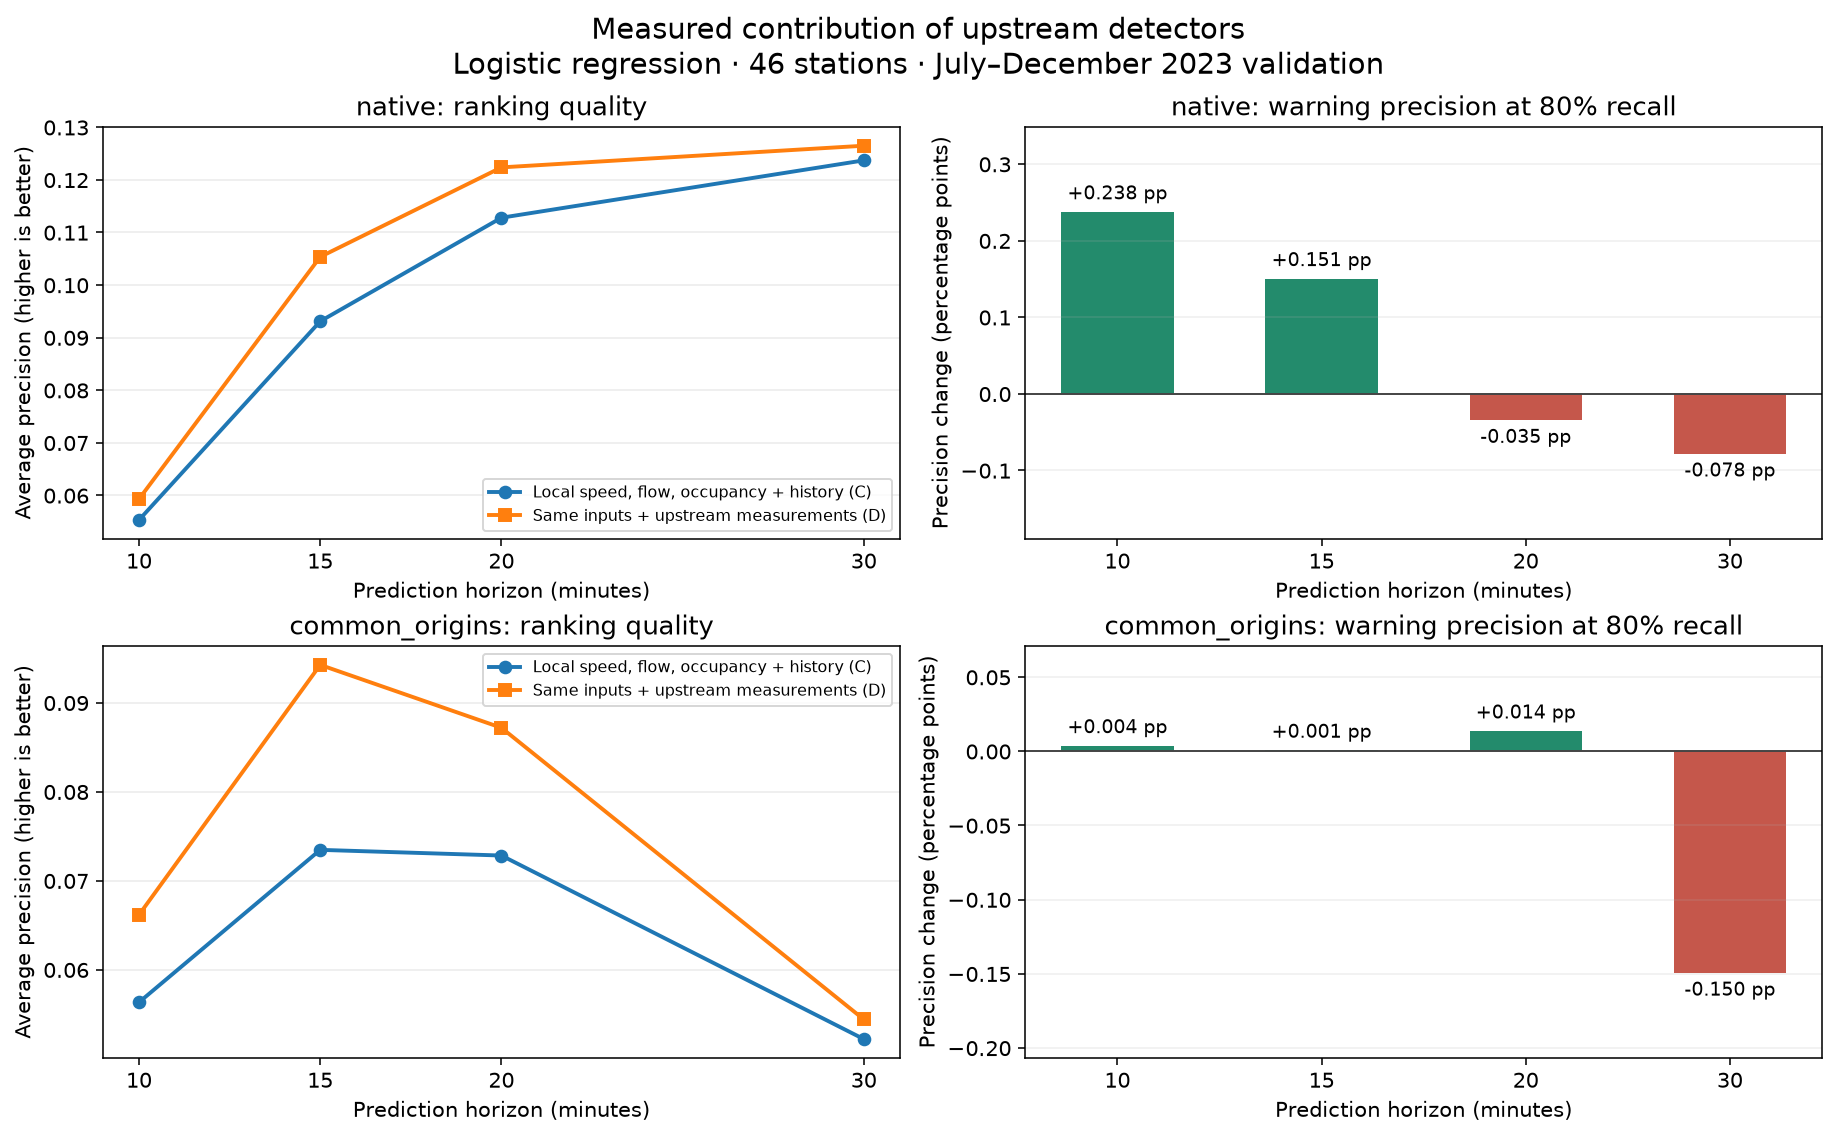

In [13]:
# Paired ablation: identical model class and rows, changing only upstream inputs.
local_name, spatial_name = "C_plus_flow_occupancy", "D_plus_upstream"
pair_keys = ["horizon_min", "cohort"]
logistic = results.loc[results.model.eq("Logistic regression")]
rank = logistic.loc[logistic.operating_point.eq("default_0.5")]
policy = logistic.loc[logistic.operating_point.eq("target_recall")]
local_rank = rank.loc[rank.feature_set.eq(local_name), pair_keys + ["n", "PR_AUC"]]
spatial_rank = rank.loc[rank.feature_set.eq(spatial_name), pair_keys + ["n", "PR_AUC"]]
upstream_comparison = local_rank.merge(spatial_rank, on=pair_keys, suffixes=("_local", "_upstream"), validate="one_to_one")
assert upstream_comparison.n_local.eq(upstream_comparison.n_upstream).all()
for feature_set, suffix in [(local_name, "local"), (spatial_name, "upstream")]:
    subset = policy.loc[policy.feature_set.eq(feature_set), pair_keys + ["Precision", "Recall"]].rename(
        columns={"Precision": f"precision80_{suffix}", "Recall": f"recall80_{suffix}"})
    upstream_comparison = upstream_comparison.merge(subset, on=pair_keys, validate="one_to_one")
upstream_comparison["AP_gain"] = upstream_comparison.PR_AUC_upstream - upstream_comparison.PR_AUC_local
upstream_comparison["AP_relative_gain_pct"] = 100 * upstream_comparison.AP_gain / upstream_comparison.PR_AUC_local
upstream_comparison["precision80_change_pp"] = 100 * (upstream_comparison.precision80_upstream - upstream_comparison.precision80_local)
upstream_comparison = upstream_comparison.sort_values(["cohort", "horizon_min"])
display(upstream_comparison[["cohort", "horizon_min", "n_local", "PR_AUC_local", "PR_AUC_upstream",
                             "AP_relative_gain_pct", "precision80_local", "precision80_upstream", "precision80_change_pp"]].round(4))

plt.rcParams.update({"font.size": 11})
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
for row, cohort in enumerate(["native", "common_origins"]):
    table = upstream_comparison.loc[upstream_comparison.cohort.eq(cohort)].sort_values("horizon_min")
    ax = axes[row, 0]
    ax.plot(table.horizon_min, table.PR_AUC_local, marker="o", linewidth=2, label="Local speed, flow, occupancy + history (C)")
    ax.plot(table.horizon_min, table.PR_AUC_upstream, marker="s", linewidth=2, label="Same inputs + upstream measurements (D)")
    ax.set(title=f"{cohort}: ranking quality", ylabel="Average precision (higher is better)",
           xlabel="Prediction horizon (minutes)", xticks=[10, 15, 20, 30])
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8, loc="best")
    ax = axes[row, 1]
    values = table.precision80_change_pp
    bars = ax.bar(table.horizon_min.astype(str), values,
                  color=["#238b6c" if v >= 0 else "#c5574b" for v in values], width=0.55)
    ax.axhline(0, color="#444444", linewidth=1)
    ax.bar_label(bars, labels=[f"{v:+.3f} pp" for v in values], padding=4, fontsize=10)
    ax.set(title=f"{cohort}: warning precision at 80% recall",
           ylabel="Precision change (percentage points)",
           xlabel="Prediction horizon (minutes)")
    ax.margins(y=0.35)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Measured contribution of upstream detectors\nLogistic regression · 46 stations · July–December 2023 validation", fontsize=15)
fig.savefig(run_dir / "upstream_information_comparison.png", dpi=180, bbox_inches="tight")
fig.savefig(run_dir / "upstream_information_comparison.svg", bbox_inches="tight")
plt.show()
upstream_comparison.to_csv(run_dir / "upstream_information_comparison.csv", index=False)


**Measured conclusion.** Upstream inputs increase average precision at all four horizons in both cohorts. Native-cohort gains are **+7.2% at 10 minutes, +13.2% at 15, +8.5% at 20, and +2.3% at 30**. Common-origin relative gains are **+17.5%, +28.3%, +19.7%, and +4.2%**, respectively. The largest relative increment is at 15 minutes, and the 30-minute increment is small.

At the 80% recall target, native precision changes from **1.61% to 1.85%** (10 min), **2.86% to 3.01%** (15 min), **4.17% to 4.13%** (20 min), and **5.69% to 5.62%** (30 min). Common-origin policy gains are near zero at 10–20 minutes and negative at 30 minutes. Better ranking therefore does not consistently improve warning precision at this recall target.

**What this establishes about the horizon.** The measurements provide incremental predictive information at fixed horizons, most clearly at 15–20 minutes by average precision. They do not establish an extension of the usable prediction horizon: that would require an agreed precision/false-alarm requirement and evidence that the upstream model meets it farther in advance than the local model. AP values across horizons cannot determine such an extension because endpoint labels and prevalence change.

**Limits.** These are paired logistic comparisons from one temporal fold, with no uncertainty intervals. The 10-minute upstream bundle still has lower native AP than the simpler history/calendar-only bundle B (0.059 versus 0.066), so an incremental C → D gain does not mean D is always the best feature set. The Random Forests were trained only with the richest feature set; their overall performance cannot be attributed specifically to upstream measurements without a C-versus-D forest ablation. Confirmation needs paired comparisons across the other development folds and episode-level warning metrics before final holdout scoring.


## 7. Verify the 30-minute reference and summarize measured takeaways

Read the original notebook's saved model-comparison table without executing it. Display its exact saved outputs alongside this run's native 30-minute estimates. Small differences can arise from package versions; large discrepancies warrant checking station subsets, feature availability, the selected fold, and class/quality definitions. The comparison is meaningful with the default all-station, first-fold, 300-tree settings. Common-origin scores will generally differ because they use a stricter evaluation population.

In [11]:
original_path = ROOT / "notebooks" / "03_congestion_onset_analysis.ipynb"
original_nb = json.loads(original_path.read_text(encoding="utf-8"))
print("Saved reference output from the original notebook:")
found_reference = False
for cell in original_nb["cells"]:
    source = "".join(cell.get("source", []))
    if cell.get("cell_type") == "code" and "display(model_comparison.round(3))" in source:
        for output in cell.get("outputs", []):
            text = output.get("data", {}).get("text/plain")
            if text:
                print("".join(text))
                found_reference = True
if not found_reference:
    print("No saved reference table available; run and save the original notebook for a numerical cross-check.")
display(ranking.loc[ranking.horizon_min.eq(30) & ranking.cohort.eq("native"),
    ["model", "feature_set", "n", "prevalence", "PR_AUC", "ROC_AUC", "Precision", "Recall", "F1"]].round(3))

for cohort in ["native", "common_origins"]:
    print(f"\nMeasured findings — {cohort}:")
    for horizon in sorted(HORIZONS):
        row = operating.loc[operating.cohort.eq(cohort) & operating.horizon_min.eq(horizon) & operating.model.eq("Random Forest")].iloc[0]
        reg = regime_metrics.loc[regime_metrics.cohort.eq(cohort) & regime_metrics.horizon_min.eq(horizon)].set_index("regime")
        stable = reg.loc["Free → Free", "MAE_mph"] if "Free → Free" in reg.index else np.nan
        onset_error = reg.loc["Free → Congested", "MAE_mph"] if "Free → Congested" in reg.index else np.nan
        print(f"{horizon:2d} min: persistence MAE stable/onset = {stable:.2f}/{onset_error:.2f} mph; "
              f"RF average precision = {row.PR_AUC:.3f}; prevalence = {row.prevalence:.2%}; "
              f"precision = {row.Precision:.2%} at recall {row.Recall:.2%}; "
              f"false warnings per true-positive row = {row.false_warnings_per_true_onset:.1f}.")

Saved reference output from the original notebook:
                 Model      Feature set  PR_AUC  ROC_AUC  Precision  Recall  \
0  Logistic regression  D_plus_upstream   0.126    0.884       0.05   0.833   
1        Random Forest  D_plus_upstream   0.322    0.918       0.17   0.659   

      F1  
0  0.094  
1  0.270  


,model,feature_set,n,prevalence,PR_AUC,ROC_AUC,Precision,Recall,F1
60,Logistic regression,A_current_speed,309745,0.014,0.060,0.818,0.042,0.705,0.080
64,Logistic regression,B_local_history,309745,0.014,0.119,0.854,0.048,0.779,0.091
68,Logistic regression,C_plus_flow_occupancy,309745,0.014,0.124,0.881,0.049,0.841,0.093
72,Logistic regression,D_plus_upstream,309745,0.014,0.126,0.884,0.050,0.833,0.094
76,Random Forest,D_plus_upstream,309745,0.014,0.322,0.918,0.170,0.659,0.270



Measured findings — native:
10 min: persistence MAE stable/onset = 1.17/7.31 mph; RF average precision = 0.151; prevalence = 0.23%; precision = 2.54% at recall 80.05%; false warnings per true-positive row = 38.4.
15 min: persistence MAE stable/onset = 1.37/9.13 mph; RF average precision = 0.211; prevalence = 0.49%; precision = 4.21% at recall 80.05%; false warnings per true-positive row = 22.7.
20 min: persistence MAE stable/onset = 1.53/10.43 mph; RF average precision = 0.255; prevalence = 0.79%; precision = 6.00% at recall 80.00%; false warnings per true-positive row = 15.7.
30 min: persistence MAE stable/onset = 1.76/12.22 mph; RF average precision = 0.322; prevalence = 1.35%; precision = 8.94% at recall 80.01%; false warnings per true-positive row = 10.2.

Measured findings — common_origins:
10 min: persistence MAE stable/onset = 1.16/7.29 mph; RF average precision = 0.247; prevalence = 0.15%; precision = 3.22% at recall 80.73%; false warnings per true-positive row = 30.0.
15 min:

## 8. Save the experiment and choose the next check

The saved tables support side-by-side comparisons without rerunning model fits. These are single-fold development results, not final holdout estimates or statistical significance tests. Rerun with other `FOLD_INDEX` values to check temporal consistency. Then assess calibration and episode-level alerts before selecting a horizon; shorter horizons trade intervention time for potentially easier prediction. The same-validation tuning of models and cutoffs can make development performance optimistic. Freeze the chosen policy before a separate final holdout analysis.

In [12]:
config = dict(horizons=HORIZONS, fold_index=FOLD_INDEX, fold=selected_fold,
              train_start=str(train_start), test_start=str(test_start), target_recall=TARGET_RECALL,
              free_flow_threshold=FREE_FLOW_THRESHOLD, congested_threshold=CONGESTED_THRESHOLD,
              regime_threshold=REGIME_THRESHOLD, target_min_observed=TARGET_MIN_OBSERVED,
              rf_trees=RF_TREES, rf_depth=RF_DEPTH, rf_min_leaf=RF_MIN_LEAF, rf_feature_set=rf_feature_set,
              random_state=RANDOM_STATE, station_ids=STATION_IDS,
              feature_file=str(FEATURE_FILE), feature_file_bytes=FEATURE_FILE.stat().st_size,
              feature_file_mtime_ns=FEATURE_FILE.stat().st_mtime_ns,
              feature_sets=FEATURE_SETS, common_origins_controls="validation eligibility only; native training per horizon",
              python=platform.python_version(), pandas=pd.__version__, sklearn=sklearn.__version__)
(run_dir / "configuration.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
results.to_csv(run_dir / "classifier_metrics.csv", index=False)
populations.to_csv(run_dir / "cohort_populations.csv", index=False)
regime_metrics.to_csv(run_dir / "persistence_by_regime.csv", index=False)
curves.to_csv(run_dir / "precision_recall_curves.csv", index=False)
feature_gains.to_csv(run_dir / "feature_gains.csv")
print("Saved experiment:", run_dir)

Saved experiment: C:\Erdos\Project\safeflow\results\congestion_horizon_comparison\2026-10-28_134810_584716
